# Lap 2 — velocity/acceleration dead reckoning vs GT

**Kernel：** `pixel-racers`

Integrate body-frame velocity `(vx, vy)`, acceleration `(ax, ay)`, and yaw rate `wz` from `/constructor0/state_estimation`, starting at the **lap-2 start** (GT), to dead-reckon pose at each `/constructor0/sensor/camera_fl/compressed_image` timestamp; compare against `gt.csv` and `track_bounds`.

Convention (dataset README): `base_link` is x-forward / y-left; `vx,vy,ax,ay` are in the body frame.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

ROOT = Path.cwd().resolve()
if ROOT.name == "odometry":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from camloc_play import DEFAULT_MCAP, camera_topic, stamp_ns_from_msg

CAMLOC = ROOT.parent / "c0_2026-10-13_22-53-42_camloc"
EXTRACTED = CAMLOC / "extracted"
LAPDATA = ROOT / "lapdata"
OUT_DIR = ROOT / "odometry"
MCAP = DEFAULT_MCAP
FL_TOPIC = camera_topic("fl")
LAP = 2

print("MCAP:", MCAP, "exists=", MCAP.is_file())
print("EXTRACTED:", EXTRACTED)

MCAP: /Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/c0_2026-10-13_22-53-42_camloc_0.mcap exists= True
EXTRACTED: /Users/hbai/SchubKI/c0_2026-10-13_22-53-42_camloc/extracted


## 1. Load lap-2 window, SE, GT, track_bounds

In [2]:
# Do not use float64 for ns; laps from JSON; read CSV timestamps as strings then int64
with open(LAPDATA / "laps.json") as f:
    laps_meta = json.load(f)
lap_row = next(L for L in laps_meta["laps"] if L["lap"] == LAP)
START_NS = int(lap_row["start_ns"])
END_NS = int(lap_row["end_ns"])
print(f"lap {LAP}: [{START_NS}, {END_NS}]  duration={lap_row['duration_s']:.2f}s")


def read_csv_ns(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, dtype={"timestamp_ns": str})
    df["timestamp_ns"] = df["timestamp_ns"].astype("int64")
    return df


se = read_csv_ns(EXTRACTED / "state_estimation.csv")
gt = read_csv_ns(EXTRACTED / "gt.csv")
se2 = se[(se["timestamp_ns"] >= START_NS) & (se["timestamp_ns"] <= END_NS)].reset_index(drop=True)
gt2 = gt[(gt["timestamp_ns"] >= START_NS) & (gt["timestamp_ns"] <= END_NS)].reset_index(drop=True)
print(f"SE lap2 rows={len(se2)}  GT lap2 rows={len(gt2)}")

with open(EXTRACTED / "track_bounds.json") as f:
    track_bounds = json.load(f)


def polyline_xy(key: str) -> np.ndarray:
    pts = track_bounds[key]["points"]
    return np.array([[p["x"], p["y"]] for p in pts], dtype=np.float64)


track_left = polyline_xy("track_left")
track_right = polyline_xy("track_right")
print("track_left/right points:", len(track_left), len(track_right))

# Lap-2 start: GT pose at start_ns (or nearest neighbor)
# Avoid gt.iloc[i] as a full Series row — int64 timestamps get promoted with float columns and lose precision
ts_gt = gt["timestamp_ns"].to_numpy(dtype=np.int64)
i0 = int(np.argmin(np.abs(ts_gt - np.int64(START_NS))))
x0 = float(gt.at[i0, "x"])
y0 = float(gt.at[i0, "y"])
yaw0 = float(gt.at[i0, "yaw"])
print(f"init GT @ idx={i0} ts={int(ts_gt[i0])}: x={x0:.4f} y={y0:.4f} yaw={yaw0:.6f}")

lap 2: [1791918444832466282, 1791918612426651869]  duration=167.59s
SE lap2 rows=17772  GT lap2 rows=17772
track_left/right points: 5914 6115
init GT @ idx=30516 ts=1791918444832466282: x=5.7104 y=3.1039 yaw=0.119635


## 2. Read camera_fl timestamps (cached)

In [3]:
stamp_cache = OUT_DIR / f"lap{LAP:02d}_fl_stamps_ns.npy"


def load_fl_stamps(mcap_path: Path, start_ns: int, end_ns: int) -> np.ndarray:
    if stamp_cache.is_file():
        stamps = np.load(stamp_cache)
        print(f"loaded cache {stamp_cache.name}: {len(stamps)} stamps")
        return stamps.astype(np.int64)

    stamps: list[int] = []
    log_start = max(0, start_ns - 2_000_000_000)
    log_end = end_ns + 2_000_000_000
    with open(mcap_path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _schema, _channel, _message, msg in reader.iter_decoded_messages(
            topics=[FL_TOPIC],
            start_time=log_start,
            end_time=log_end,
        ):
            stamp = stamp_ns_from_msg(msg)
            if start_ns <= stamp <= end_ns:
                stamps.append(stamp)
    arr = np.asarray(stamps, dtype=np.int64)
    np.save(stamp_cache, arr)
    print(f"extracted & cached {len(arr)} FL stamps -> {stamp_cache}")
    return arr


fl_stamps = load_fl_stamps(MCAP, START_NS, END_NS)
print(
    f"FL frames={len(fl_stamps)}  median dt={np.median(np.diff(fl_stamps)) / 1e6:.2f} ms"
    if len(fl_stamps) > 1
    else f"FL frames={len(fl_stamps)}"
)

loaded cache lap02_fl_stamps_ns.npy: 1676 stamps
FL frames=1676  median dt=100.00 ms


## 3. Dead reckoning (body velocity + acceleration + wz)

Integrate over SE sample intervals (**do not** use SE `x,y`; only `vx,vy,ax,ay,wz`):

$$
\Delta p_{\text{body}} = v\,\Delta t + \tfrac12 a\,\Delta t^2,\quad
\text{yaw} \leftarrow \text{yaw} + \omega_z\,\Delta t
$$

Rotate displacement into `map` using mid-interval heading. Reset $v$ from measured velocity each SE step (avoids double-integration drift); acceleration enters only the in-interval quadratic term.

In [4]:
def dead_reckon_se(
    se_df: pd.DataFrame,
    *,
    x0: float,
    y0: float,
    yaw0: float,
    use_accel: bool = True,
) -> pd.DataFrame:
    ts = se_df["timestamp_ns"].to_numpy(dtype=np.int64)
    vx = se_df["vx_mps"].to_numpy(dtype=np.float64)
    vy = se_df["vy_mps"].to_numpy(dtype=np.float64)
    ax = se_df["ax_mps2"].to_numpy(dtype=np.float64)
    ay = se_df["ay_mps2"].to_numpy(dtype=np.float64)
    wz = se_df["wz_radps"].to_numpy(dtype=np.float64)

    n = len(se_df)
    xs = np.empty(n, dtype=np.float64)
    ys = np.empty(n, dtype=np.float64)
    yaws = np.empty(n, dtype=np.float64)
    xs[0], ys[0], yaws[0] = x0, y0, yaw0

    x, y, yaw = x0, y0, yaw0
    for i in range(n - 1):
        dt = (ts[i + 1] - ts[i]) * 1e-9
        if dt <= 0:
            xs[i + 1], ys[i + 1], yaws[i + 1] = x, y, yaw
            continue
        dx_b = vx[i] * dt
        dy_b = vy[i] * dt
        if use_accel:
            dx_b += 0.5 * ax[i] * dt * dt
            dy_b += 0.5 * ay[i] * dt * dt
        yaw_mid = yaw + 0.5 * wz[i] * dt
        c, s = np.cos(yaw_mid), np.sin(yaw_mid)
        x = x + c * dx_b - s * dy_b
        y = y + s * dx_b + c * dy_b
        yaw = yaw + wz[i] * dt
        xs[i + 1], ys[i + 1], yaws[i + 1] = x, y, yaw

    return pd.DataFrame(
        {"timestamp_ns": ts, "x": xs, "y": ys, "yaw": yaws}
    )


dr_se = dead_reckon_se(se2, x0=x0, y0=y0, yaw0=yaw0, use_accel=True)
print(dr_se.head(3))
print("...")
print(dr_se.tail(2))

          timestamp_ns         x         y       yaw
0  1791918444832466282  5.710400  3.103900  0.119635
1  1791918444841989136  5.940414  3.130758  0.119569
2  1791918444851551786  6.171471  3.157567  0.119477
...
              timestamp_ns         x         y       yaw
17770  1791918612417133033 -9.764260 -1.588216  6.389152
17771  1791918612426651869 -9.499872 -1.561016  6.389148


## 4. Interpolate to camera_fl timestamps and align with GT

In [5]:
def wrap_pi(a: np.ndarray) -> np.ndarray:
    return (a + np.pi) % (2 * np.pi) - np.pi


def interp_pose(pose_df: pd.DataFrame, query_ns: np.ndarray) -> pd.DataFrame:
    """Linear interp x,y; unwrap+interp yaw."""
    t = pose_df["timestamp_ns"].to_numpy(dtype=np.float64)
    x = pose_df["x"].to_numpy(dtype=np.float64)
    y = pose_df["y"].to_numpy(dtype=np.float64)
    yaw = np.unwrap(pose_df["yaw"].to_numpy(dtype=np.float64))
    q = query_ns.astype(np.float64)
    return pd.DataFrame(
        {
            "timestamp_ns": query_ns.astype(np.int64),
            "x": np.interp(q, t, x),
            "y": np.interp(q, t, y),
            "yaw": wrap_pi(np.interp(q, t, yaw)),
        }
    )


pred_fl = interp_pose(dr_se, fl_stamps)
gt_fl = interp_pose(gt2[["timestamp_ns", "x", "y", "yaw"]], fl_stamps)

err_xy = np.hypot(pred_fl["x"] - gt_fl["x"], pred_fl["y"] - gt_fl["y"])
err_yaw = wrap_pi(pred_fl["yaw"].to_numpy() - gt_fl["yaw"].to_numpy())
err_yaw_deg = np.abs(err_yaw) * 180.0 / np.pi

summary = pd.Series(
    {
        "n_fl": len(fl_stamps),
        "xy_mean_m": float(err_xy.mean()),
        "xy_median_m": float(np.median(err_xy)),
        "xy_p95_m": float(np.percentile(err_xy, 95)),
        "xy_end_m": float(err_xy.iloc[-1]),
        "yaw_mean_deg": float(err_yaw_deg.mean()),
        "yaw_median_deg": float(np.median(err_yaw_deg)),
        "yaw_p95_deg": float(np.percentile(err_yaw_deg, 95)),
        "yaw_end_deg": float(err_yaw_deg[-1]),
    }
)
print(summary.to_string())

pred_path = OUT_DIR / f"lap{LAP:02d}_fl_pred_pose.csv"
pred_fl.to_csv(pred_path, index=False)
print("wrote", pred_path)

n_fl              1676.000000
xy_mean_m           10.219052
xy_median_m          8.263928
xy_p95_m            22.957521
xy_end_m            15.706147
yaw_mean_deg         1.290966
yaw_median_deg       1.453004
yaw_p95_deg          2.192214
yaw_end_deg          2.121197
wrote /Users/hbai/SchubKI/PixelRacers/odometry/lap02_fl_pred_pose.csv


## 5. Error vs time

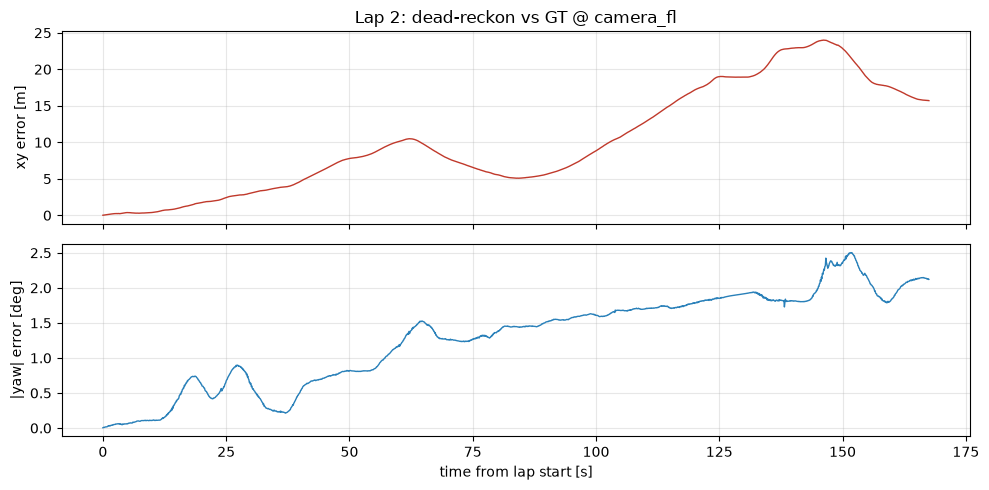

In [6]:
t_rel = (fl_stamps - fl_stamps[0]) * 1e-9

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(t_rel, err_xy, color="#c0392b", lw=1.0)
axes[0].set_ylabel("xy error [m]")
axes[0].grid(True, alpha=0.3)
axes[0].set_title(f"Lap {LAP}: dead-reckon vs GT @ camera_fl")

axes[1].plot(t_rel, err_yaw_deg, color="#2980b9", lw=1.0)
axes[1].set_ylabel("|yaw| error [deg]")
axes[1].set_xlabel("time from lap start [s]")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Trajectory comparison (overlay track_bounds)

saved /Users/hbai/SchubKI/PixelRacers/odometry/lap02_traj_vs_gt.png


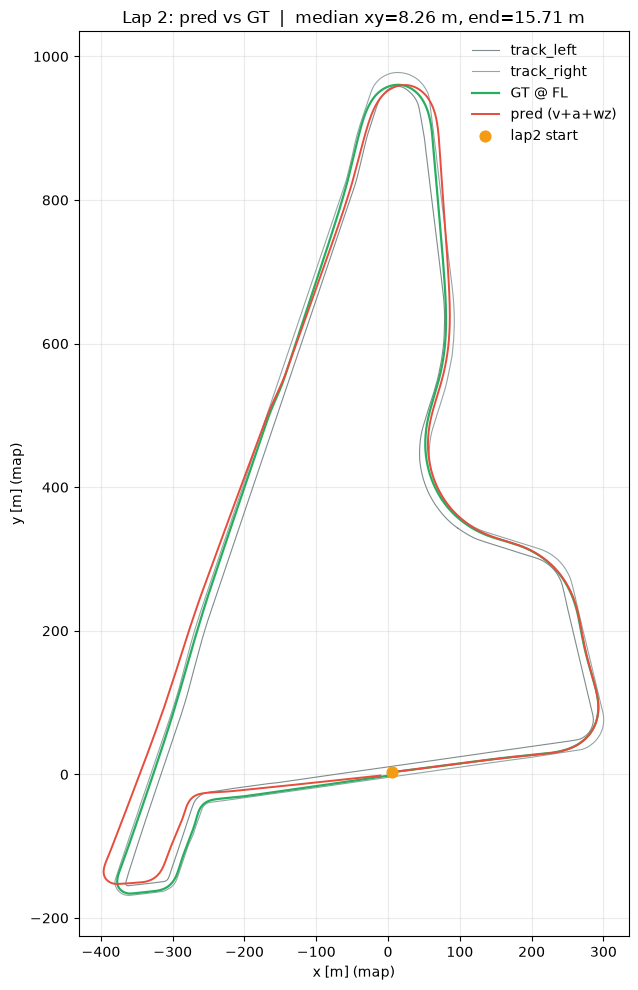

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.plot(track_left[:, 0], track_left[:, 1], color="#7f8c8d", lw=0.8, label="track_left")
ax.plot(track_right[:, 0], track_right[:, 1], color="#95a5a6", lw=0.8, label="track_right")
ax.plot(gt_fl["x"], gt_fl["y"], color="#27ae60", lw=1.6, label="GT @ FL")
ax.plot(pred_fl["x"], pred_fl["y"], color="#e74c3c", lw=1.4, label="pred (v+a+wz)")
ax.scatter([x0], [y0], c="#f39c12", s=60, zorder=5, label="lap2 start")
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x [m] (map)")
ax.set_ylabel("y [m] (map)")
ax.set_title(
    f"Lap {LAP}: pred vs GT  |  median xy={summary['xy_median_m']:.2f} m, "
    f"end={summary['xy_end_m']:.2f} m"
)
ax.legend(loc="best", frameon=False)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig_path = OUT_DIR / f"lap{LAP:02d}_traj_vs_gt.png"
fig.savefig(fig_path, dpi=150)
print("saved", fig_path)
plt.show()

## 7. (Optional) velocity only, no acceleration — drift comparison

In [8]:
dr_se_v = dead_reckon_se(se2, x0=x0, y0=y0, yaw0=yaw0, use_accel=False)
pred_v = interp_pose(dr_se_v, fl_stamps)
err_v = np.hypot(pred_v["x"] - gt_fl["x"], pred_v["y"] - gt_fl["y"])
print(
    f"v only : median={np.median(err_v):.3f} m  p95={np.percentile(err_v,95):.3f} m  end={err_v.iloc[-1]:.3f} m"
)
print(
    f"v+a    : median={summary['xy_median_m']:.3f} m  p95={summary['xy_p95_m']:.3f} m  end={summary['xy_end_m']:.3f} m"
)

v only : median=8.372 m  p95=22.885 m  end=15.728 m
v+a    : median=8.264 m  p95=22.958 m  end=15.706 m
